# MLP baseline for WEAR activity recognition

**Model owner:** Dishank Shah (MLP, feedforward family)

This notebook trains a multi-layer perceptron on the inertial data of the
[3rd WEAR Dataset Challenge](https://www.kaggle.com/competitions/3rd-wear-dataset-challenge-hasca-2026).
It is the simplest of our four models (MLP, 1D-CNN, BiLSTM, Transformer) and
is the baseline the other three are compared against.

**Task, as defined by the Kaggle test set:** each sample is a 1-second window
(50 samples at 50 Hz) of 3-axis acceleration from one of four limbs, and the
model predicts one of 19 classes (18 workouts plus `null`).

**Why an MLP is a fair baseline:** it sees the same raw window as the other
models but has no notion of time order. Every one of the 150 values is just
another input. Whatever the CNN, BiLSTM and Transformer gain over this
number is what modelling the temporal structure is worth.

**Protocol (kept the same as the BiLSTM branch so the numbers can be compared):**
- windows of 50 samples with a stride of 25, kept only if at least 80% of
  the samples share one label
- one sample per window per limb, with the limb given to the model
- subjects 0, 1, 8, 13 and 15 held out for validation (the split produced
  by `GroupShuffleSplit(test_size=0.2, random_state=42)` in the BiLSTM notebook)
- only video-free inputs: the VideoMAE features are not used

In [1]:
import os
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    classification_report,
    confusion_matrix,
)

print("PyTorch:", torch.__version__)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

PyTorch: 2.12.1+cpu
Device: cpu


## 1. Configuration

In [2]:
# The notebook runs unchanged on Kaggle (data attached under /kaggle/input)
# or locally with the inertial files copied into WEAR_kaggle/data/.
KAGGLE_PATH = Path("/kaggle/input/competitions/3rd-wear-dataset-challenge-hasca-2026")
LOCAL_PATH = Path("..") / "data"
DATA_DIR = Path(os.environ.get(
    "WEAR_DATA_DIR",
    KAGGLE_PATH if KAGGLE_PATH.exists() else LOCAL_PATH,
))

RESULTS_DIR = Path("..") / "results"
OUTPUT_DIR = Path("..") / "outputs"     # model weights and submission file (not committed)
RESULTS_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

# Windowing: 1 s windows at 50 Hz with 50% overlap, as in the BiLSTM branch.
SENSOR_HZ = 50
WINDOW = 50
STRIDE = 25
MIN_AGREEMENT = 0.8          # majority label must cover at least 40 of the 50 samples

# Held-out validation subjects, shared with the BiLSTM branch.
VAL_SUBJECTS = [0, 1, 8, 13, 15]

# MLP hyperparameters.
HIDDEN_SIZES = [512, 256, 128]
DROPOUT = 0.3
BATCH_SIZE = 512
EPOCHS = int(os.environ.get("WEAR_EPOCHS", 40))
LR = 1e-3
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05
PATIENCE = 6                 # early stopping on validation macro F1

SEED = 42

print("Data directory:", DATA_DIR)

Data directory: ..\data


In [3]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

# Label encoding required by the competition's submission format.
LABELS = [
    "null", "jogging", "jogging (rotating arms)", "jogging (skipping)",
    "jogging (sidesteps)", "jogging (butt-kicks)", "stretching (triceps)",
    "stretching (lunging)", "stretching (shoulders)", "stretching (hamstrings)",
    "stretching (lumbar rotation)", "push-ups", "push-ups (complex)", "sit-ups",
    "sit-ups (complex)", "burpees", "lunges", "lunges (complex)", "bench-dips",
]
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}
NUM_CLASSES = len(LABELS)

# The four Bangle.js watches; each gives one 3-axis stream.
LOCATIONS = ["right_arm", "right_leg", "left_leg", "left_arm"]
LOCATION_TO_ID = {name: i for i, name in enumerate(LOCATIONS)}
SENSOR_COLUMNS = [f"{loc}_acc_{axis}" for loc in LOCATIONS for axis in "xyz"]

## 2. Load the recordings and cut them into windows

Each training CSV is one recording session (`sbj_0_2.csv` and `sbj_14_2.csv`
are repeat sessions of subjects 0 and 14, so they share a subject id and
always land on the same side of the split).

A window keeps its majority label if that label covers at least 80% of it;
windows that straddle two activities are dropped. Each kept window then
produces up to four samples, one per limb. A sample is dropped if its limb has
missing readings in that window: some recordings have gaps (the left-arm
columns contain NaNs), which is what made the BiLSTM run's loss go to NaN.

In [4]:
def window_recording(path):
    df = pd.read_csv(path, low_memory=False)
    df[SENSOR_COLUMNS] = df[SENSOR_COLUMNS].apply(pd.to_numeric, errors="coerce")
    labels = df["label"].fillna("null").astype(str).str.strip().map(LABEL_TO_ID)
    if labels.isna().any():
        raise ValueError(f"{path.name}: unknown labels {set(df['label'][labels.isna()])}")

    label_ids = labels.to_numpy(dtype=np.int64)
    values = df[SENSOR_COLUMNS].to_numpy(dtype=np.float32)
    subject = int(df["sbj_id"].iloc[0])

    starts = np.arange(0, len(df) - WINDOW + 1, STRIDE)
    idx = starts[:, None] + np.arange(WINDOW)                  # (n_windows, 50)

    # Majority label and its share for every window at once.
    counts = np.stack([(label_ids[idx] == c).sum(axis=1) for c in range(NUM_CLASSES)], axis=1)
    majority = counts.argmax(axis=1)
    keep = counts.max(axis=1) >= MIN_AGREEMENT * WINDOW
    idx, majority = idx[keep], majority[keep]

    windows = values[idx]                                       # (n_kept, 50, 12)
    X, y, loc = [], [], []
    for loc_id in range(len(LOCATIONS)):
        sensor = windows[:, :, 3 * loc_id: 3 * loc_id + 3]      # (n_kept, 50, 3)
        finite = np.isfinite(sensor).all(axis=(1, 2))
        X.append(sensor[finite])
        y.append(majority[finite])
        loc.append(np.full(finite.sum(), loc_id))
    X, y, loc = np.concatenate(X), np.concatenate(y), np.concatenate(loc)
    return X, y, loc, np.full(len(y), subject), int(keep.sum()), int(len(starts))


train_files = sorted((DATA_DIR / "train" / "inertial_feat").glob("*.csv"))
print("Recordings found:", len(train_files))
assert train_files, f"No CSV files under {DATA_DIR / 'train' / 'inertial_feat'}"

parts = []
for path in train_files:
    X, y, loc, sbj, kept, total = window_recording(path)
    parts.append((X, y, loc, sbj))
    print(f"{path.stem:>9}: {kept:5d}/{total:5d} windows kept -> {len(y):6d} limb samples")

X_all = np.concatenate([p[0] for p in parts])
y_all = np.concatenate([p[1] for p in parts])
loc_all = np.concatenate([p[2] for p in parts])
sbj_all = np.concatenate([p[3] for p in parts])
del parts

print("\nTotal samples:", X_all.shape)

Recordings found: 24


    sbj_0:  5508/ 5588 windows kept ->  22032 limb samples


  sbj_0_2:  4437/ 4481 windows kept ->  17748 limb samples


    sbj_1:  5472/ 5555 windows kept ->  21888 limb samples


   sbj_10:  7905/ 7969 windows kept ->  29592 limb samples


...

    sbj_5:  4215/ 4300 windows kept ->  16860 limb samples


    sbj_6:  4946/ 5006 windows kept ->  19784 limb samples


    sbj_7:  5640/ 5705 windows kept ->  22560 limb samples


    sbj_8:  4937/ 4989 windows kept ->  19748 limb samples


    sbj_9:  4281/ 4331 windows kept ->  17124 limb samples

Total samples: (545964, 50, 3)


In [5]:
class_counts = pd.Series(y_all).map(dict(enumerate(LABELS))).value_counts()
print(class_counts.to_string())
print(f"\nnull share: {class_counts['null'] / len(y_all):.1%}")

null                            216357
jogging                          19880
jogging (sidesteps)              19584
stretching (lunging)             19388
sit-ups (complex)                19124
lunges (complex)                 19108
sit-ups                          18920
lunges                           18575
stretching (triceps)             18508
push-ups (complex)               18308
stretching (lumbar rotation)     18196
burpees                          18192
jogging (skipping)               18068
stretching (hamstrings)          18066
stretching (shoulders)           17755
jogging (rotating arms)          17400
push-ups                         17032
jogging (butt-kicks)             17032
bench-dips                       16471

null share: 39.6%


## 3. Subject-wise split and normalisation

Mean and standard deviation are computed per limb and per axis from the
training subjects only, then applied to both splits (and later to the test
windows), so nothing about the validation subjects leaks into training.

In [6]:
is_val = np.isin(sbj_all, VAL_SUBJECTS)

X_tr, y_tr, loc_tr = X_all[~is_val], y_all[~is_val], loc_all[~is_val]
X_va, y_va, loc_va = X_all[is_val], y_all[is_val], loc_all[is_val]
sbj_va = sbj_all[is_val]

print("Train subjects:", sorted(set(sbj_all[~is_val].tolist())))
print("Val subjects:  ", sorted(set(sbj_va.tolist())))
print(f"Train samples: {len(y_tr):,}   Val samples: {len(y_va):,}")

# Per-limb, per-axis statistics: shape (4 limbs, 3 axes).
loc_mean = np.stack([X_tr[loc_tr == l].mean(axis=(0, 1)) for l in range(len(LOCATIONS))])
loc_std = np.stack([X_tr[loc_tr == l].std(axis=(0, 1)) for l in range(len(LOCATIONS))])
loc_std[loc_std < 1e-6] = 1.0
print(pd.DataFrame(loc_mean, index=LOCATIONS, columns=["mean_x", "mean_y", "mean_z"]).round(3))

Train subjects: [2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 14, 16, 17, 18, 19, 20, 21]
Val subjects:   [0, 1, 8, 13, 15]
Train samples: 412,456   Val samples: 133,508


           mean_x  mean_y  mean_z
right_arm   0.417   0.413  -0.231
right_leg   0.729  -0.002   0.160
left_leg    0.629   0.031   0.153
left_arm   -0.407   0.387  -0.228


## 4. Turning a window into an MLP input

The MLP takes a flat vector, so each normalised 50 x 3 window becomes 150
numbers. A one-hot code for the limb is appended (4 more inputs), because the
same movement looks different from a wrist and from an ankle. That gives 154
inputs per sample.

In [7]:
def to_features(X, loc):
    X = (X - loc_mean[loc][:, None, :]) / loc_std[loc][:, None, :]
    flat = X.reshape(len(X), -1)                                 # (N, 150)
    one_hot = np.eye(len(LOCATIONS), dtype=np.float32)[loc]      # (N, 4)
    return np.concatenate([flat, one_hot], axis=1).astype(np.float32)


F_tr = torch.from_numpy(to_features(X_tr, loc_tr))
F_va = torch.from_numpy(to_features(X_va, loc_va))
Y_tr = torch.from_numpy(y_tr)
Y_va = torch.from_numpy(y_va)

train_loader = DataLoader(TensorDataset(F_tr, Y_tr), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(F_va, Y_va), batch_size=4096)

INPUT_SIZE = F_tr.shape[1]
print("Input size:", INPUT_SIZE)

Input size: 154


## 5. Model

Three hidden layers (512, 256, 128). Each layer is Linear, then BatchNorm,
ReLU and Dropout. BatchNorm keeps training stable at a fairly high learning
rate; dropout is the main guard against overfitting to the 17 training
subjects.

In [8]:
class MLP(nn.Module):
    def __init__(self, input_size, hidden_sizes, num_classes, dropout):
        super().__init__()
        layers, prev = [], input_size
        for size in hidden_sizes:
            layers += [nn.Linear(prev, size), nn.BatchNorm1d(size), nn.ReLU(), nn.Dropout(dropout)]
            prev = size
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


model = MLP(INPUT_SIZE, HIDDEN_SIZES, NUM_CLASSES, DROPOUT).to(DEVICE)
print(model)
print(f"\nTrainable parameters: {sum(p.numel() for p in model.parameters()):,}")

MLP(
  (net): Sequential(
    (0): Linear(in_features=154, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=128, out_features=19, bias=True)
  )
)

Trainable parameters: 247,827


## 6. Training

`null` makes up a large share of the samples, so the loss is class-weighted
(inverse frequency, clipped to [0.25, 5]) in the same way as the BiLSTM
branch. Model selection uses validation **macro F1**, which treats all 19
classes equally and is not inflated by getting `null` right.

In [9]:
counts = np.bincount(y_tr, minlength=NUM_CLASSES).clip(min=1)
class_weights = np.clip(len(y_tr) / (NUM_CLASSES * counts), 0.25, 5.0)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)


def run_epoch(loader, train):
    model.train(train)
    total_loss, preds, targets = 0.0, [], []
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            preds.append(logits.argmax(1).cpu())
            targets.append(yb.cpu())
    preds, targets = torch.cat(preds).numpy(), torch.cat(targets).numpy()
    return (total_loss / len(targets),
            f1_score(targets, preds, average="macro", zero_division=0),
            accuracy_score(targets, preds))


history, best_f1, best_state, wait = [], -1.0, None, 0
start = time.time()
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_f1, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_f1, va_acc = run_epoch(val_loader, train=False)
    scheduler.step()
    history.append(dict(epoch=epoch, train_loss=tr_loss, train_f1=tr_f1, train_acc=tr_acc,
                        val_loss=va_loss, val_f1=va_f1, val_acc=va_acc))
    improved = va_f1 > best_f1
    print(f"Epoch {epoch:02d} | train loss {tr_loss:.4f} F1 {tr_f1:.4f} | "
          f"val loss {va_loss:.4f} F1 {va_f1:.4f} acc {va_acc:.4f}{'  *' if improved else ''}")
    if improved:
        best_f1, wait = va_f1, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping: no improvement for {PATIENCE} epochs.")
            break

print(f"\nTraining time: {time.time() - start:.0f} s, best val macro F1: {best_f1:.4f}")
model.load_state_dict(best_state)
torch.save(best_state, OUTPUT_DIR / "mlp_baseline.pt")

Epoch 01 | train loss 1.9195 F1 0.3707 | val loss 1.6213 F1 0.4629 acc 0.4429  *


Epoch 02 | train loss 1.6713 F1 0.4505 | val loss 1.5534 F1 0.4964 acc 0.4689  *


Epoch 03 | train loss 1.6063 F1 0.4747 | val loss 1.5177 F1 0.5161 acc 0.4953  *


Epoch 04 | train loss 1.5692 F1 0.4898 | val loss 1.4888 F1 0.5240 acc 0.4944  *


Epoch 05 | train loss 1.5421 F1 0.4978 | val loss 1.4864 F1 0.5319 acc 0.5087  *


...

Epoch 21 | train loss 1.4045 F1 0.5526 | val loss 1.4310 F1 0.5589 acc 0.5503


Epoch 22 | train loss 1.4022 F1 0.5531 | val loss 1.4255 F1 0.5596 acc 0.5478


Epoch 23 | train loss 1.3981 F1 0.5560 | val loss 1.4281 F1 0.5578 acc 0.5467


Epoch 24 | train loss 1.3940 F1 0.5571 | val loss 1.4225 F1 0.5599 acc 0.5510


Epoch 25 | train loss 1.3896 F1 0.5573 | val loss 1.4226 F1 0.5588 acc 0.5494
Early stopping: no improvement for 6 epochs.

Training time: 523 s, best val macro F1: 0.5621


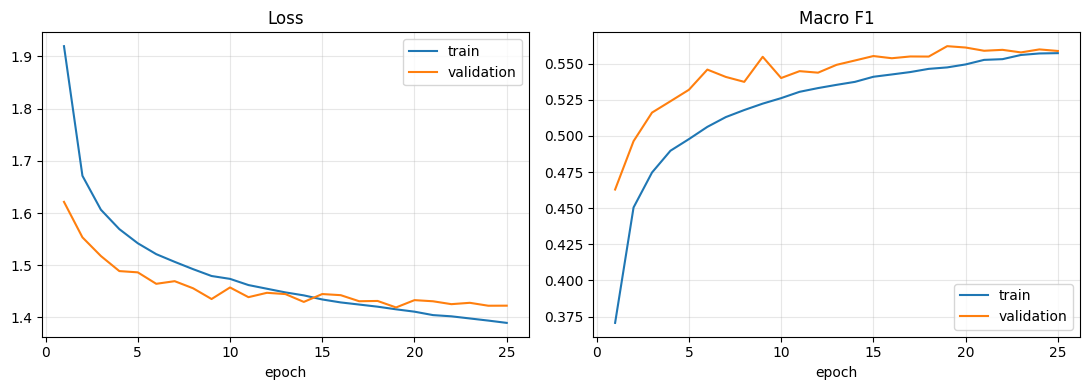

In [10]:
hist = pd.DataFrame(history)
hist.to_csv(RESULTS_DIR / "mlp_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist.epoch, hist.train_loss, label="train")
axes[0].plot(hist.epoch, hist.val_loss, label="validation")
axes[0].set(title="Loss", xlabel="epoch")
axes[1].plot(hist.epoch, hist.train_f1, label="train")
axes[1].plot(hist.epoch, hist.val_f1, label="validation")
axes[1].set(title="Macro F1", xlabel="epoch")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "mlp_training_curves.png", dpi=150)
plt.show()

## 7. Validation results

In [11]:
model.eval()
with torch.no_grad():
    y_pred = torch.cat([model(xb.to(DEVICE)).argmax(1).cpu() for xb, _ in val_loader]).numpy()

prec, rec, f1, _ = precision_recall_fscore_support(y_va, y_pred, average="macro", zero_division=0)
no_null = y_va != 0
results = pd.DataFrame([{
    "model": "MLP",
    "validation_accuracy": accuracy_score(y_va, y_pred),
    "macro_precision": prec,
    "macro_recall": rec,
    "macro_f1": f1,
    "weighted_f1": f1_score(y_va, y_pred, average="weighted", zero_division=0),
    "macro_f1_without_null": f1_score(y_va[no_null], y_pred[no_null], labels=range(1, NUM_CLASSES),
                                      average="macro", zero_division=0),
    "parameters": sum(p.numel() for p in model.parameters()),
    "epochs_trained": len(history),
}])
results.to_csv(RESULTS_DIR / "mlp_results.csv", index=False)
print(results.T.to_string(header=False))

model                       MLP
validation_accuracy    0.550364
macro_precision        0.531895
macro_recall           0.623938
macro_f1               0.562095
weighted_f1            0.552834
macro_f1_without_null  0.646314
parameters               247827
epochs_trained               25


In [12]:
report = classification_report(y_va, y_pred, labels=range(NUM_CLASSES), target_names=LABELS,
                               digits=3, zero_division=0)
(RESULTS_DIR / "mlp_classification_report.txt").write_text(report)
print(report)

                              precision    recall  f1-score   support

                        null      0.829     0.395     0.535     46820
                     jogging      0.704     0.815     0.756      5572
     jogging (rotating arms)      0.548     0.512     0.529      4920
          jogging (skipping)      0.612     0.853     0.713      4680
         jogging (sidesteps)      0.779     0.707     0.741      4944
        jogging (butt-kicks)      0.874     0.751     0.808      4544
        stretching (triceps)      0.363     0.627     0.460      4780
        stretching (lunging)      0.455     0.622     0.525      4892
      stretching (shoulders)      0.200     0.313     0.244      4600
     stretching (hamstrings)      0.509     0.726     0.598      4436
stretching (lumbar rotation)      0.669     0.834     0.742      4624
                    push-ups      0.395     0.716     0.509      4476
          push-ups (complex)      0.408     0.493     0.446      4828
                   

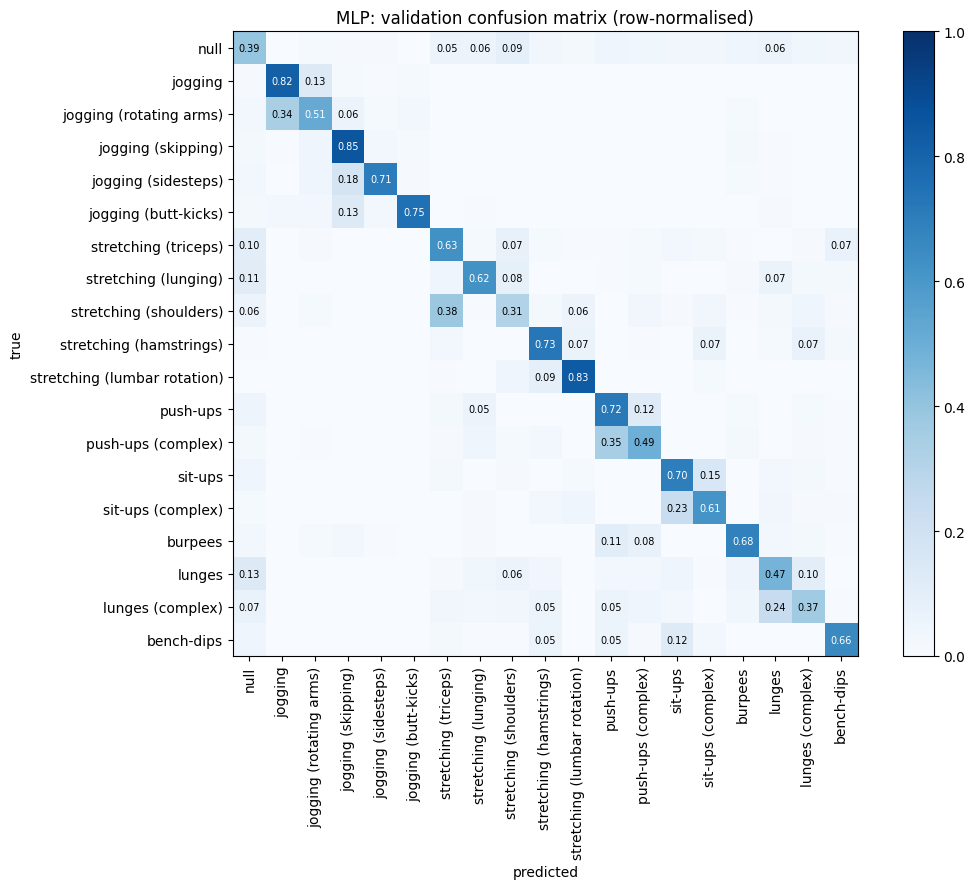

In [13]:
# Row-normalised confusion matrix: each row shows where the windows of one true class went.
cm = confusion_matrix(y_va, y_pred, labels=range(NUM_CLASSES), normalize="true")
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES), LABELS, rotation=90)
ax.set_yticks(range(NUM_CLASSES), LABELS)
ax.set(xlabel="predicted", ylabel="true", title="MLP: validation confusion matrix (row-normalised)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j] >= 0.05:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 0.5 else "black")
fig.colorbar(im, fraction=0.046)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "mlp_confusion_matrix.png", dpi=150)
plt.show()

### Error analysis by limb and by subject

The test set mixes windows from all four limbs, so it matters whether the MLP
is much better from some limbs than others. The per-subject numbers show how
much the score moves from one unseen person to the next.

In [14]:
per_loc = pd.DataFrame([{
    "limb": name,
    "samples": int((loc_va == i).sum()),
    "accuracy": accuracy_score(y_va[loc_va == i], y_pred[loc_va == i]),
    "macro_f1": f1_score(y_va[loc_va == i], y_pred[loc_va == i], average="macro", zero_division=0),
} for i, name in enumerate(LOCATIONS)])

per_sbj = pd.DataFrame([{
    "subject": s,
    "samples": int((sbj_va == s).sum()),
    "accuracy": accuracy_score(y_va[sbj_va == s], y_pred[sbj_va == s]),
    "macro_f1": f1_score(y_va[sbj_va == s], y_pred[sbj_va == s], average="macro", zero_division=0),
} for s in VAL_SUBJECTS])

per_loc.to_csv(RESULTS_DIR / "mlp_per_limb.csv", index=False)
per_sbj.to_csv(RESULTS_DIR / "mlp_per_subject.csv", index=False)
print(per_loc.round(4).to_string(index=False))
print()
print(per_sbj.round(4).to_string(index=False))

     limb  samples  accuracy  macro_f1
right_arm    33377    0.5696    0.5527
right_leg    33377    0.5210    0.5617
 left_leg    33377    0.5272    0.5633
 left_arm    33377    0.5837    0.5817

 subject  samples  accuracy  macro_f1
       0    39780    0.5518    0.5550
       1    21888    0.4926    0.5000
       8    19748    0.5747    0.5924
      13    31476    0.5604    0.5629
      15    20616    0.5703    0.5971


## 8. Kaggle test predictions

The test windows are already cut to 50 x 3 and come with their limb, so they
go through exactly the same normalisation and flattening. The submission file
is written to `outputs/` and is not committed.

In [15]:
test_X_path = DATA_DIR / "test" / "test_inertial_data.npy"
test_meta_path = DATA_DIR / "test" / "test_meta_data.csv"

if test_X_path.exists() and test_meta_path.exists():
    X_test = np.load(test_X_path).astype(np.float32)
    meta = pd.read_csv(test_meta_path)
    loc_col = next(c for c in meta.columns if "location" in c)
    loc_test = meta[loc_col].map(LOCATION_TO_ID)
    assert loc_test.notna().all(), f"Unknown limb names: {set(meta[loc_col][loc_test.isna()])}"
    loc_test = loc_test.to_numpy(dtype=np.int64)

    # Missing readings in a test window are set to that limb's training mean (0 after scaling).
    X_test = np.where(np.isfinite(X_test), X_test, loc_mean[loc_test][:, None, :])

    with torch.no_grad():
        F_test = torch.from_numpy(to_features(X_test, loc_test))
        test_pred = torch.cat([model(F_test[i:i + 4096].to(DEVICE)).argmax(1).cpu()
                               for i in range(0, len(F_test), 4096)]).numpy()

    submission = pd.DataFrame({"id": meta["id"], "target_value": test_pred}).sort_values("id")
    submission.to_csv(OUTPUT_DIR / "submission_mlp.csv", index=False)
    print("Test windows:", X_test.shape, "| written to outputs/submission_mlp.csv")
    print(submission.target_value.map(dict(enumerate(LABELS))).value_counts().head(10).to_string())
else:
    print("Test files not found; skipping the submission step.")

Test windows: (12234, 50, 3) | written to outputs/submission_mlp.csv
target_value
null                      2747
stretching (lunging)       957
lunges                     734
sit-ups                    618
stretching (shoulders)     591
push-ups                   561
stretching (triceps)       543
lunges (complex)           542
sit-ups (complex)          536
push-ups (complex)         529
